In [10]:
model_path = "/content/best_model.pt"
class_names_path = "/content/class_names.txt"

In [11]:
import torch
import timm

device = "cuda" if torch.cuda.is_available() else "cpu"

with open(class_names_path) as f:
    class_names = f.read().split("\n")

model = timm.create_model("convnext_tiny", pretrained=False, num_classes=len(class_names))
model.load_state_dict(torch.load(model_path, map_location=device))
model = model.to(device)
model.eval()

print("Model loaded. Classes:", class_names)

Model loaded. Classes: ['CORAL', 'CORAL_BL']


In [12]:
from torchvision import transforms
from PIL import Image

mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)

transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

def predict(image_path):
    image = Image.open(image_path).convert("RGB")
    tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(tensor)
        probabilities = torch.softmax(output, dim=1)[0]

    best = probabilities.argmax().item()

    plt.imshow(image)
    plt.title(f"{class_names[best]}  ({probabilities[best]*100:.1f}%)")
    plt.axis("off")
    plt.show()

    for name, p in zip(class_names, probabilities):
        print(f"{name}: {p*100:.1f}%")

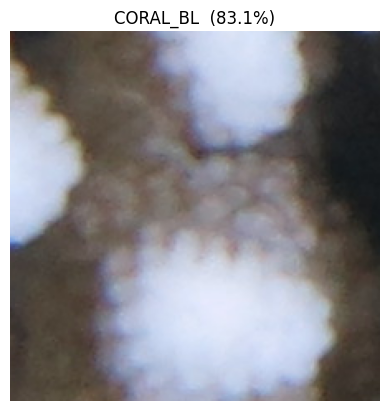

CORAL: 16.9%
CORAL_BL: 83.1%


In [15]:
coral_bl = "/content/LaehouShallow2015IMG_2757_8196.PNG"
predict(coral_bl)

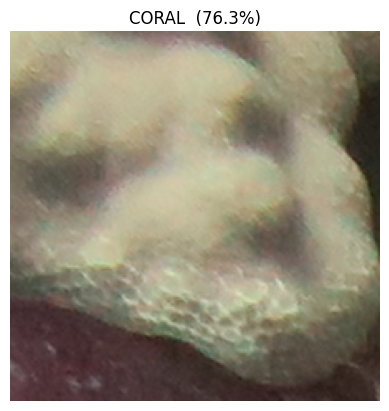

CORAL: 76.3%
CORAL_BL: 23.7%


In [16]:
coral = "/content/LIS-B001_2019_28_12224.PNG"
predict(coral)